In [1]:
!pip install -q qwen-vl-utils transformers accelerate gradio


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 63.2 MB/s eta 0:00:00


In [2]:
try:
    from transformers import Qwen2VLForConditionalGeneration, AutoProcessor
    print("✅ Success! Libraries imported correctly.")
except ImportError as e:
    print(f"❌ Still failing: {e}")


✅ Success! Libraries imported correctly.


In [3]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [13]:
!ls  /content/drive/MyDrive/model_ocr

qwen2_vl_2b


In [17]:
import torch
import os
from google.colab import drive

# --- 1. Verify Drive & GPU ---
print("Step 1: Checking Hardware...")
if not torch.cuda.is_available():
    print("❌ ERROR: GPU not detected! Go to Runtime > Change runtime type > T4 GPU.")
else:
    print(f"✅ GPU: {torch.cuda.get_device_name(0)}")

# --- 2. Verify Files ---
MODEL_PATH = "/content/drive/MyDrive/model_ocr/qwen2_vl_2b"
print(f"Step 2: Checking Path {MODEL_PATH}...")
if not os.path.exists(MODEL_PATH):
    print("❌ ERROR: Model path not found. Is your Drive mounted?")
    drive.mount('/content/drive')
else:
    print(f"✅ Files found: {os.listdir(MODEL_PATH)[:3]}...")

# --- 3. Test Loading with Error Catching ---
try:
    print("Step 3: Loading Transformers...")
    from transformers import Qwen2VLForConditionalGeneration, AutoProcessor
    from qwen_vl_utils import process_vision_info

    print("Step 4: Loading Model (This might take 2 mins)...")
    # Using low_cpu_mem_usage to prevent silent system RAM crashes
    model = Qwen2VLForConditionalGeneration.from_pretrained(
        MODEL_PATH,
        torch_dtype=torch.bfloat16,
        device_map="auto",
        low_cpu_mem_usage=True
    )
    print("✅ MODEL LOADED SUCCESSFULLY!")
except Exception as e:
    print(f"❌ CRITICAL ERROR DURING LOAD: {e}")


Step 1: Checking Hardware...
✅ GPU: Tesla T4
Step 2: Checking Path /content/drive/MyDrive/model_ocr/qwen2_vl_2b...
✅ Files found: ['.cache', '.gitattributes', 'chat_template.json']...
Step 3: Loading Transformers...
Step 4: Loading Model (This might take 2 mins)...
❌ CRITICAL ERROR DURING LOAD: No such file or directory: /content/drive/MyDrive/model_ocr/qwen2_vl_2b/model-00001-of-00002.safetensors


In [5]:
import gradio as gr
import torch
from qwen_vl_utils import process_vision_info

# Step 1: Kill any stuck background processes
try:
    gr.close_all()
except:
    pass

def transcribe_handwriting(image):
    if image is None:
        return "Please upload an image."

    # FIX: Ensure processor is loaded
    global processor
    if 'processor' not in globals():
        processor = AutoProcessor.from_pretrained(MODEL_PATH)

    # Step 2: Build the prompt (Simplified to avoid SyntaxErrors)
    # We tell the model specifically about "IoT" to fix the "Jot" error
    my_prompt = "Transcribe this technical handwriting. Note: The text is about 'IoT' (Internet of Things). Do not write 'Jot'. Ensure you transcribe 'IoT Domain Model' and the bullet points exactly."

    # Step 3: Create the message list line-by-line
    # This prevents the "unmatched }" error by avoiding deep nesting
    user_content = []
    user_content.append({"type": "image", "image": image})
    user_content.append({"type": "text", "text": my_prompt})

    messages = [{"role": "user", "content": user_content}]

    try:
        # Step 4: Run the Model
        text_template = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        image_inputs, _ = process_vision_info(messages)

        inputs = processor(
            text=[text_template],
            images=image_inputs,
            padding=True,
            return_tensors="pt"
        ).to("cuda")

        with torch.no_grad():
            generated_ids = model.generate(
                **inputs,
                max_new_tokens=512,
                do_sample=False,
                repetition_penalty=1.2
            )

        # Step 5: Clean the output
        input_len = inputs.input_ids.shape[-1]
        output_ids = generated_ids[:, input_len:]
        decoded_text = processor.batch_decode(output_ids, skip_special_tokens=True)

        return decoded_text[0]

    except Exception as e:
        return f"Model Error: {str(e)}"

# Step 6: Launch the Interface
demo = gr.Interface(
    fn=transcribe_handwriting,
    inputs=gr.Image(type="pil"),
    outputs=gr.Textbox(label="Handwritten Text Recognition", lines=8),
    title="Hybrid OCR with LLM"
)

# Launching with 'inline=False' to force a new window, which is more stable
demo.launch(share=True, inline=False, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://85e640fb3b545519ae.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://85e640fb3b545519ae.gradio.live


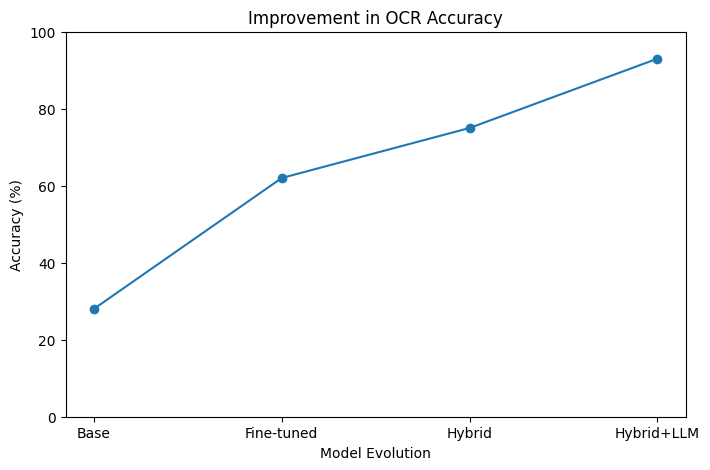

In [6]:
import matplotlib.pyplot as plt

models = ["Base", "Fine-tuned", "Hybrid", "Hybrid+LLM"]
accuracy = [28, 62, 75, 93]

plt.figure(figsize=(8, 5))
plt.plot(models, accuracy, marker='o')

plt.xlabel("Model Evolution")
plt.ylabel("Accuracy (%)")
plt.title("Improvement in OCR Accuracy")

plt.ylim(0, 100)

plt.show()

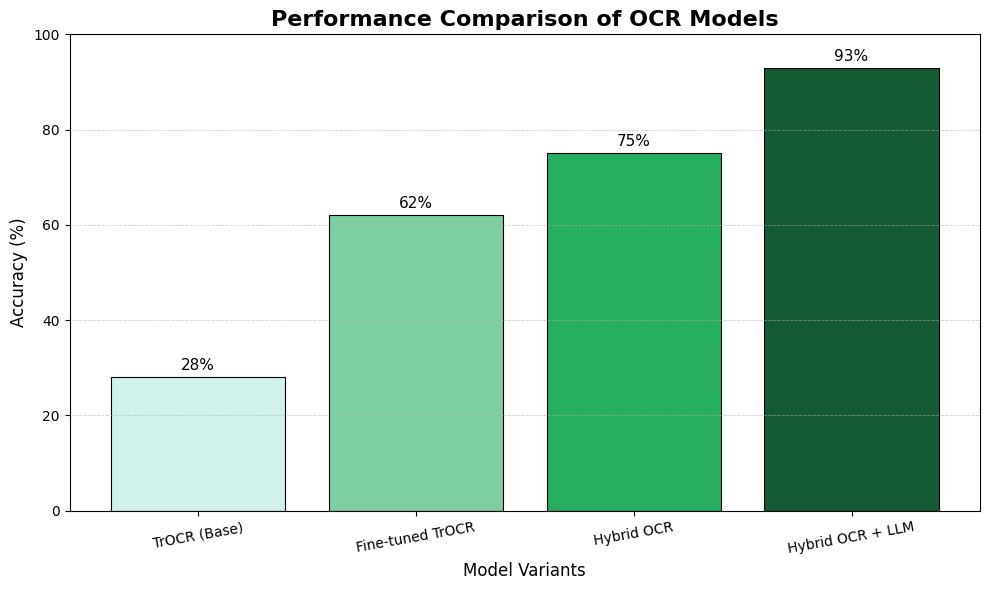

In [7]:
import matplotlib.pyplot as plt

models = [
    "TrOCR (Base)",
    "Fine-tuned TrOCR",
    "Hybrid OCR",
    "Hybrid OCR + LLM"
]

accuracy = [28, 62, 75, 93]

# Green gradient shades
colors = ["#D1F2EB", "#7DCEA0", "#27AE60", "#145A32"]

plt.figure(figsize=(10, 6))

bars = plt.bar(models, accuracy, color=colors, edgecolor='black', linewidth=0.8)

plt.title("Performance Comparison of OCR Models", fontsize=16, fontweight='bold')
plt.xlabel("Model Variants", fontsize=12)
plt.ylabel("Accuracy (%)", fontsize=12)

plt.ylim(0, 100)

plt.grid(axis='y', linestyle='--', linewidth=0.6, alpha=0.6)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 1.5,
        f"{height}%",
        ha='center',
        fontsize=11
    )

plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig("ocr_green_shades.png", dpi=300, bbox_inches='tight')

plt.show()